In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Material Intensity",
)


# ---
# Prepare data
# ---

tech_cols = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydro",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Solar Thermal",
    "Wind Onshore",
    "Wind Offshore",
]

# Aggregate by material group and convert to t/MW
df_grouped = (
    df.groupby("Group")[tech_cols]
    .sum()
    / 1000
)

df_grouped = df_grouped.rename(
    columns={
        "Hydro": "Hydropower",
    }
)

# Transpose for plotting
df_plot = df_grouped.T

technology_order = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydropower",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Solar Thermal",
    "Wind Onshore",
    "Wind Offshore",
]

df_plot = (
    df_plot
    .reindex(technology_order)
    .fillna(0)
)


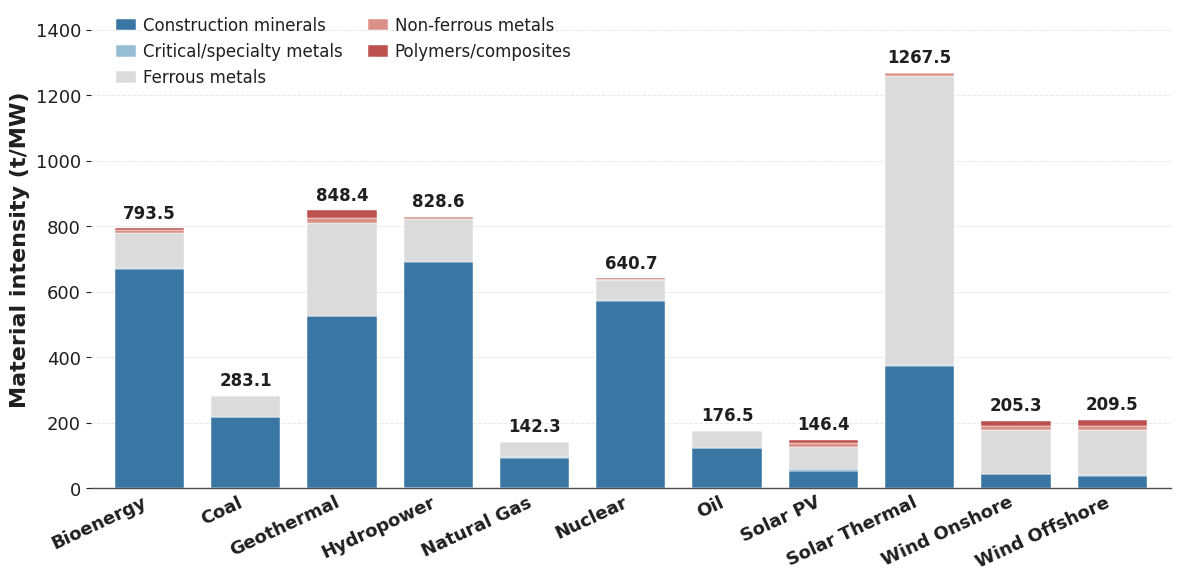

In [3]:
# ---
# SI Figure 7
# ---

# Material intensity by technology and material group


# ---
# Palette
# ---

PALETTE = [
    "#2F6F9F",  # Muted blue
    "#8FBBD3",  # Pale blue
    "#D9D9D9",  # Neutral grey
    "#D98B82",  # Muted salmon
    "#B94745",  # Muted red
]

colors = [
    (
        PALETTE[index]
        if index < len(PALETTE)
        else "#BDBDBD"
    )
    for index in range(
        len(df_plot.columns)
    )
]


# ---
# Style
# ---

COLOR_TEXT = "#1F1F1F"
COLOR_GRID = "#D9D9D9"
COLOR_AXIS = "#4D4D4D"
COLOR_BACKGROUND = "white"

FONT_BASE = 13
FONT_TICKS = 13
FONT_TECH = 13
FONT_AXIS_LABEL = 16
FONT_VALUE = 12
FONT_LEGEND = 12

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": FONT_BASE,
        "axes.edgecolor": COLOR_AXIS,
        "axes.labelcolor": COLOR_TEXT,
        "xtick.color": COLOR_TEXT,
        "ytick.color": COLOR_TEXT,
    }
)


# ---
# Figure
# ---

fig, ax = plt.subplots(
    figsize=(12, 6),
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND
)

ax.set_facecolor(
    COLOR_BACKGROUND
)


# ---
# Bars
# ---

df_plot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.72,
    color=colors,
    edgecolor="white",
    linewidth=0.4,
)

for patch in ax.patches:
    patch.set_linewidth(
        0.35
    )

    patch.set_edgecolor(
        "white"
    )

    patch.set_alpha(
        0.95
    )


# ---
# Total labels
# ---

totals = df_plot.sum(
    axis=1
)

y_offset = totals.max() * 0.015

for index, total in enumerate(
    totals
):
    ax.text(
        index,
        total + y_offset,
        f"{total:.1f}",
        ha="center",
        va="bottom",
        fontsize=FONT_VALUE,
        fontweight="bold",
        color=COLOR_TEXT,
    )


# ---
# Axes and labels
# ---

ax.set_xlabel(
    ""
)

ax.set_ylabel(
    "Material intensity (t/MW)",
    fontweight="bold",
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
)

ax.set_xticklabels(
    df_plot.index,
    rotation=25,
    ha="right",
    fontsize=FONT_TECH,
    fontweight="bold",
)

ax.tick_params(
    axis="x",
    length=0,
)

ax.tick_params(
    axis="y",
    labelsize=FONT_TICKS,
)


# ---
# Grid and spines
# ---

ax.yaxis.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    color=COLOR_GRID,
    alpha=0.55,
)

ax.xaxis.grid(
    False
)

ax.set_axisbelow(
    True
)

for spine in [
    "top",
    "right",
    "left",
]:
    ax.spines[spine].set_visible(
        False
    )

ax.spines["bottom"].set_color(
    COLOR_AXIS
)

ax.spines["bottom"].set_linewidth(
    1.0
)

# Add headroom for value labels
ax.set_ylim(
    0,
    totals.max() * 1.15,
)


# ---
# Legend
# ---

legend = ax.legend(
    bbox_to_anchor=(
        0.01,
        1.02,
    ),
    loc="upper left",
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=2,
    columnspacing=1.2,
    handlelength=1.2,
    handletextpad=0.4,
)

for text in legend.get_texts():
    text.set_color(
        COLOR_TEXT
    )


# ---
# Layout and save
# ---

plt.tight_layout()

plt.savefig(
    "figures/si/figure-7.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/si/figure-7.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
